In [9]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [10]:
df = yf.download('MSFT',
    start='2000-01-01')


df

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2000-01-03,35.377022,36.002996,33.992291,35.623618,53228400
2000-01-04,34.181969,35.547730,34.068155,34.466502,54119000
2000-01-05,34.542385,35.320110,33.195592,33.726722,64059600
2000-01-06,33.385284,34.561357,32.892093,34.049196,54976600
2000-01-07,33.821571,34.068167,32.569623,32.967970,62013600
...,...,...,...,...,...
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800


In [11]:
# df = pd.DataFrame(df["Close"]["AAPL"])
# df.rename(columns={'AAPL':'close'}, inplace=True)
df.columns = df.columns.droplevel(level=1)
df.rename(columns={'Close':'close'}, inplace=True)
df


Price,close,High,Low,Open,Volume
Date,,,,,
2000-01-03,35.377022,36.002996,33.992291,35.623618,53228400
2000-01-04,34.181969,35.547730,34.068155,34.466502,54119000
2000-01-05,34.542385,35.320110,33.195592,33.726722,64059600
2000-01-06,33.385284,34.561357,32.892093,34.049196,54976600
2000-01-07,33.821571,34.068167,32.569623,32.967970,62013600
...,...,...,...,...,...
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800
2026-11-05,535.929993,557.619995,532.679993,554.940002,42507900


In [12]:
df['simple_rtn'] = df["close"].pct_change()
df['log_rtn'] = np.log(df["close"]/df["close"].shift(1))
df

Price,close,High,Low,Open,Volume,simple_rtn,log_rtn
Date,,,,,,,
2000-01-03,35.377022,36.002996,33.992291,35.623618,53228400,NaN,NaN
2000-01-04,34.181969,35.547730,34.068155,34.466502,54119000,-0.033780,-0.034364
2000-01-05,34.542385,35.320110,33.195592,33.726722,64059600,0.010544,0.010489
2000-01-06,33.385284,34.561357,32.892093,34.049196,54976600,-0.033498,-0.034072
2000-01-07,33.821571,34.068167,32.569623,32.967970,62013600,0.013068,0.012984
...,...,...,...,...,...,...,...
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200,0.027351,0.026983
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800,0.066815,0.064678
2026-11-05,535.929993,557.619995,532.679993,554.940002,42507900,-0.035750,-0.036405


In [13]:
df_rolling = df[['simple_rtn']].rolling(window=21).agg(['mean', 'std'])
df_rolling.columns = df_rolling.columns.droplevel()
df_rolling

,mean,std
Date,,
2000-01-03,NaN,NaN
2000-01-04,NaN,NaN
2000-01-05,NaN,NaN
2000-01-06,NaN,NaN
2000-01-07,NaN,NaN
...,...,...
2026-11-03,-0.000276,0.014885
2026-11-04,0.002532,0.020858
2026-11-05,0.000789,0.022472


In [14]:
df_outliers = df.join(df_rolling)
df_outliers

,close,High,Low,Open,Volume,simple_rtn,log_rtn,mean,std
Date,,,,,,,,,
2000-01-03,35.377022,36.002996,33.992291,35.623618,53228400,NaN,NaN,NaN,NaN
2000-01-04,34.181969,35.547730,34.068155,34.466502,54119000,-0.033780,-0.034364,NaN,NaN
2000-01-05,34.542385,35.320110,33.195592,33.726722,64059600,0.010544,0.010489,NaN,NaN
2000-01-06,33.385284,34.561357,32.892093,34.049196,54976600,-0.033498,-0.034072,NaN,NaN
2000-01-07,33.821571,34.068167,32.569623,32.967970,62013600,0.013068,0.012984,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200,0.027351,0.026983,-0.000276,0.014885
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800,0.066815,0.064678,0.002532,0.020858
2026-11-05,535.929993,557.619995,532.679993,554.940002,42507900,-0.035750,-0.036405,0.000789,0.022472


In [15]:
def indentify_outliers(row, n_sigmas=3):
    x = row['simple_rtn']
    mu = row['mean']
    sigma = row['std']
    if (x > mu + 3 * sigma) | (x < mu - 3 * sigma):
        return 1
    else:
        return 0

In [16]:
df_outliers['outlier'] = df_outliers.apply(indentify_outliers,axis=1)
df_outliers

,close,High,Low,Open,Volume,simple_rtn,log_rtn,mean,std,outlier
Date,,,,,,,,,,
2000-01-03,35.377022,36.002996,33.992291,35.623618,53228400,NaN,NaN,NaN,NaN,0
2000-01-04,34.181969,35.547730,34.068155,34.466502,54119000,-0.033780,-0.034364,NaN,NaN,0
2000-01-05,34.542385,35.320110,33.195592,33.726722,64059600,0.010544,0.010489,NaN,NaN,0
2000-01-06,33.385284,34.561357,32.892093,34.049196,54976600,-0.033498,-0.034072,NaN,NaN,0
2000-01-07,33.821571,34.068167,32.569623,32.967970,62013600,0.013068,0.012984,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...
2026-11-03,520.989990,523.440002,507.820007,509.010010,20010200,0.027351,0.026983,-0.000276,0.014885,0
2026-11-04,555.799988,559.150024,542.299988,543.700012,50807800,0.066815,0.064678,0.002532,0.020858,1
2026-11-05,535.929993,557.619995,532.679993,554.940002,42507900,-0.035750,-0.036405,0.000789,0.022472,0


In [17]:
outliers = df_outliers.loc[df_outliers['outlier'] == 1, ['simple_rtn']]
outliers

,simple_rtn
Date,
2000-09-14,-0.035715
2000-10-19,0.195652
2000-11-30,-0.118155
2002-05-08,0.111178
2003-10-24,-0.079557
2004-03-25,0.031954
2004-04-23,0.061271
2005-01-13,-0.019044
2006-01-03,0.026386


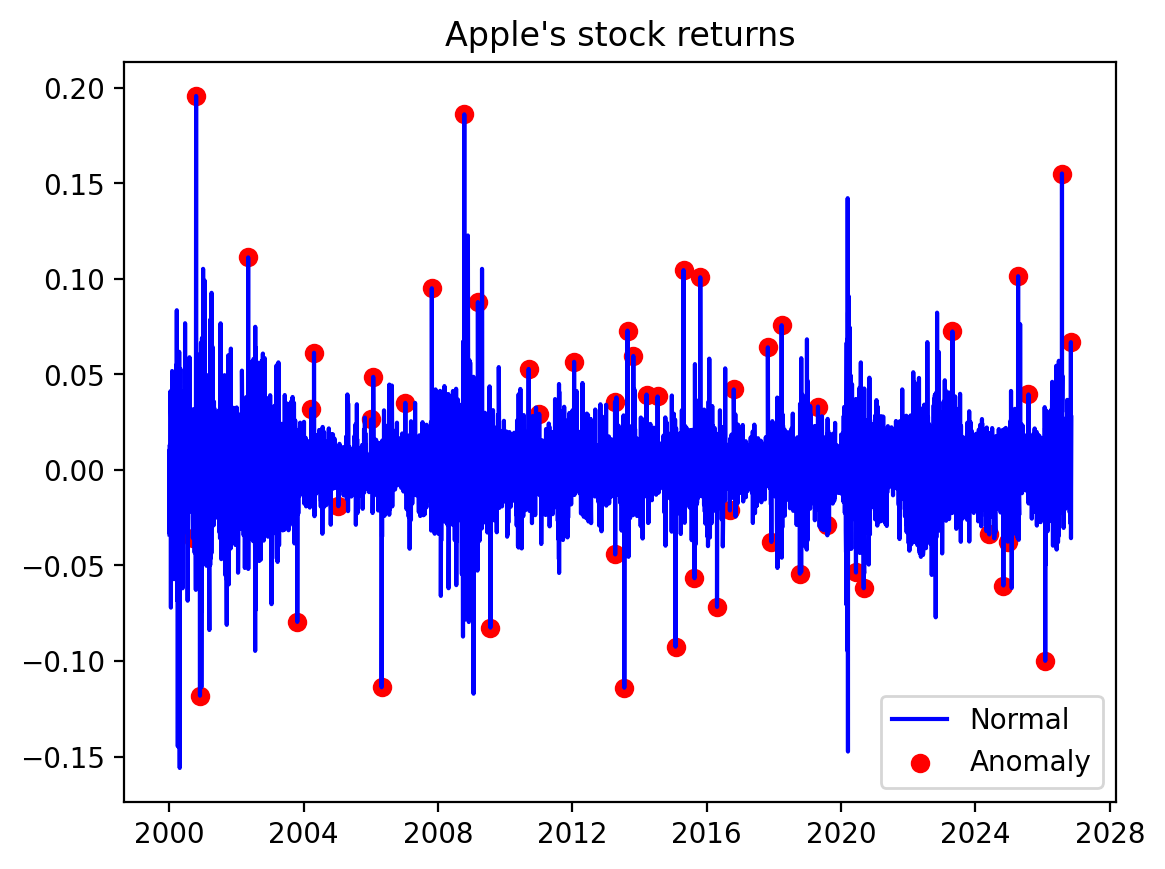

In [18]:
fig, ax = plt.subplots()
ax.plot(df_outliers.index, df_outliers.simple_rtn, color='blue', label='Normal')
ax.scatter(outliers.index, outliers.simple_rtn, color='red', label='Anomaly')
ax.set_title("Apple's stock returns")
ax.legend(loc='lower right')

# Investigating stylized facts of asset returns

In [19]:
import pandas as pd
import numpy as np
import yfinance as yf
import seaborn as sns
import scipy.stats as scs
import statsmodels.api as sm
import statsmodels.tsa.api as smt

In [20]:
r_range = np.linspace(df["log_rtn"].min(), df["log_rtn"].max(), num=1000)
mu = df.log_rtn.mean()
sigma = df.log_rtn.std()
norm_pdf = scs.norm.pdf(r_range, loc=mu, scale=sigma)
norm_pdf

array([9.11108780e-17, 1.07328342e-16, 1.26389952e-16, 1.48786873e-16,
       1.75093742e-16, 2.05982618e-16, 2.42239222e-16, 2.84781840e-16,
       3.34683313e-16, 3.93196613e-16, 4.61784570e-16, 5.42154424e-16,
       6.36297966e-16, 7.46538146e-16, 8.75583185e-16, 1.02658937e-15,
       1.20323388e-15, 1.40979927e-15, 1.65127136e-15, 1.93345273e-15,
       2.26309408e-15, 2.64804644e-15, 3.09743732e-15, 3.62187449e-15,
       4.23368172e-15, 4.94717138e-15, 5.77895942e-15, 6.74832942e-15,
       7.87765295e-15, 9.19287498e-15, 1.07240740e-14, 1.25061085e-14,
       1.45793621e-14, 1.69906030e-14, 1.97939744e-14, 2.30521350e-14,
       2.68375733e-14, 3.12341200e-14, 3.63386881e-14, 4.22632757e-14,
       4.91372678e-14, 5.71100835e-14, 6.63542166e-14, 7.70687289e-14,
       8.94832619e-14, 1.03862640e-13, 1.20512154e-13, 1.39783619e-13,
       1.62082322e-13, 1.87874986e-13, 2.17698888e-13, 2.52172313e-13,
       2.92006510e-13, 3.38019383e-13, 3.91151154e-13, 4.52482270e-13,
      

Text(0.5, 1.0, 'Q-Q plot')

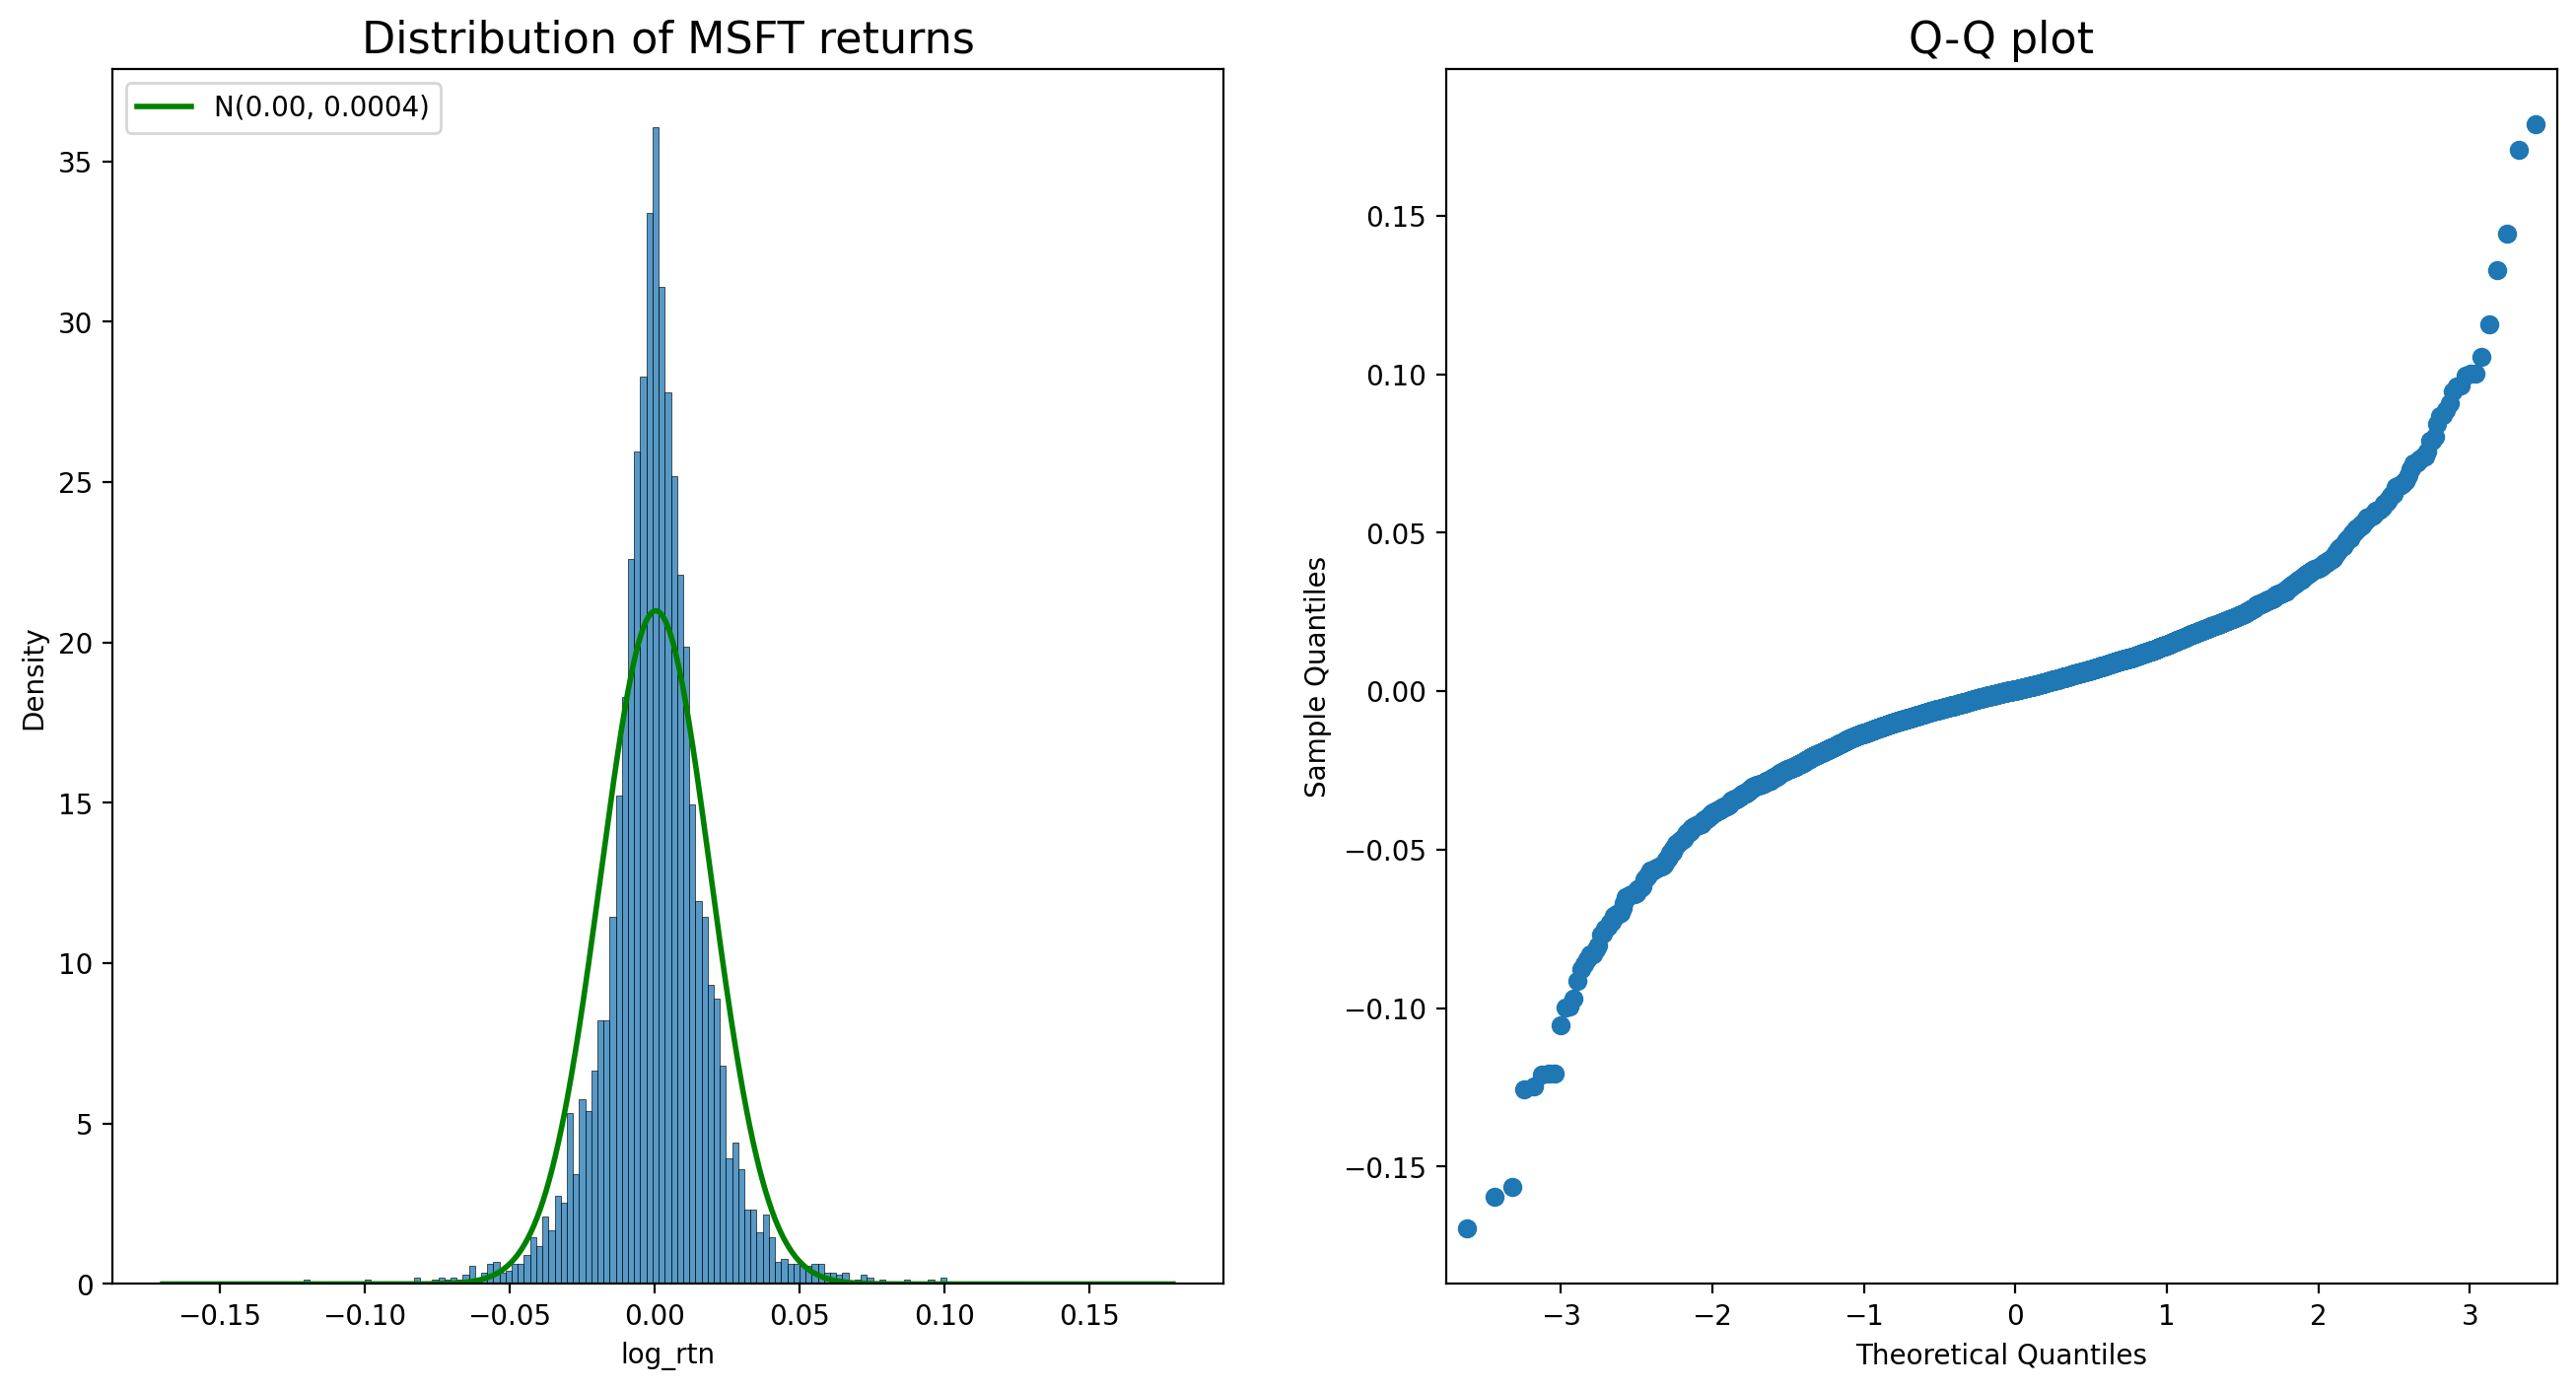

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
# histogram
sns.histplot(df.log_rtn, kde=False, stat="density" ,ax=ax[0])
ax[0].set_title('Distribution of MSFT returns', fontsize=16)
ax[0].plot(r_range, norm_pdf, 'g', lw=2,
label=f'N({mu:.2f}, {sigma**2:.4f})')
ax[0].legend(loc='upper left');
# Q-Q plot
qq = sm.qqplot(df.log_rtn.values ,line='s', ax=ax[1])
ax[1].set_title('Q-Q plot', fontsize = 16)

In [22]:
df["log_rtn"].idxmin()

Timestamp('2000-04-24 00:00:00')

# Volatility clustering

<Axes: title={'center': 'Daily MSFT returns'}, xlabel='Date'>

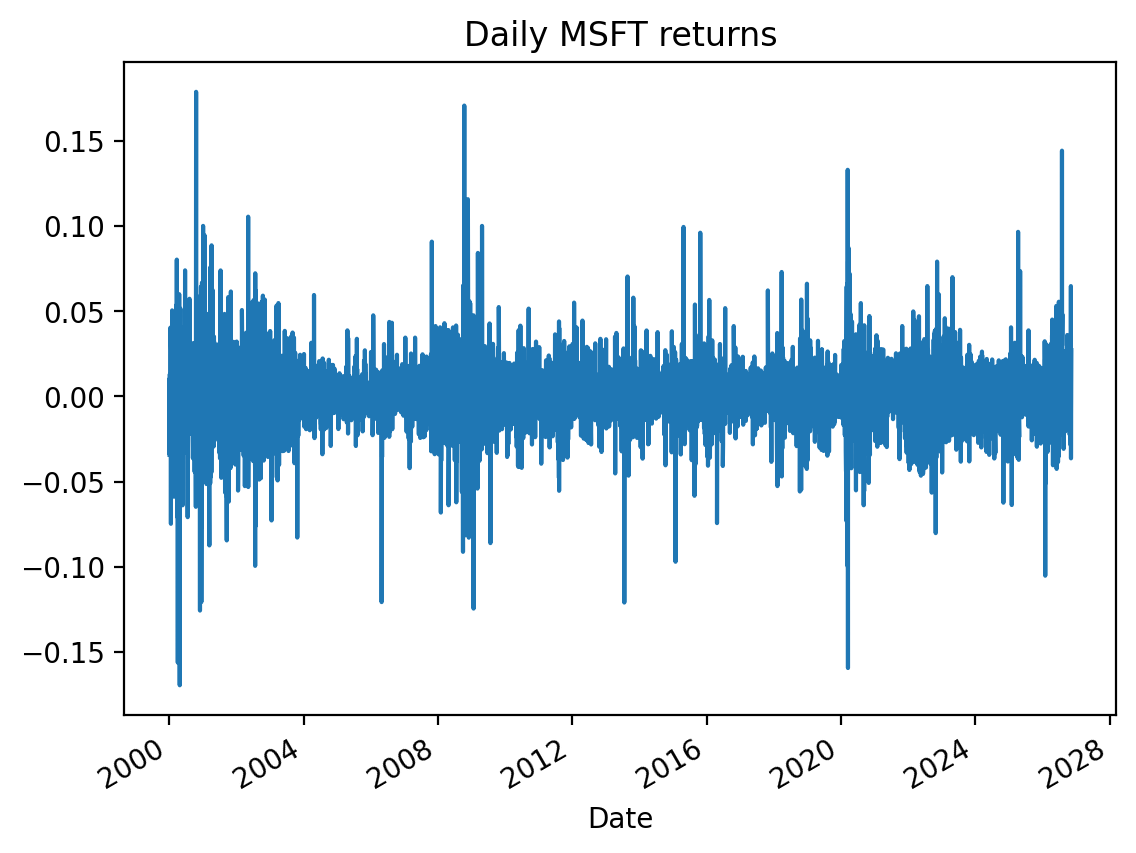

In [26]:
df.log_rtn.plot(title='Daily MSFT returns')

# Absence of autocorrelation in returns

In [27]:
N_LAGS = 50
SIGNIFICANCE_LEVEL = 0.05

(-0.1, 1.1)

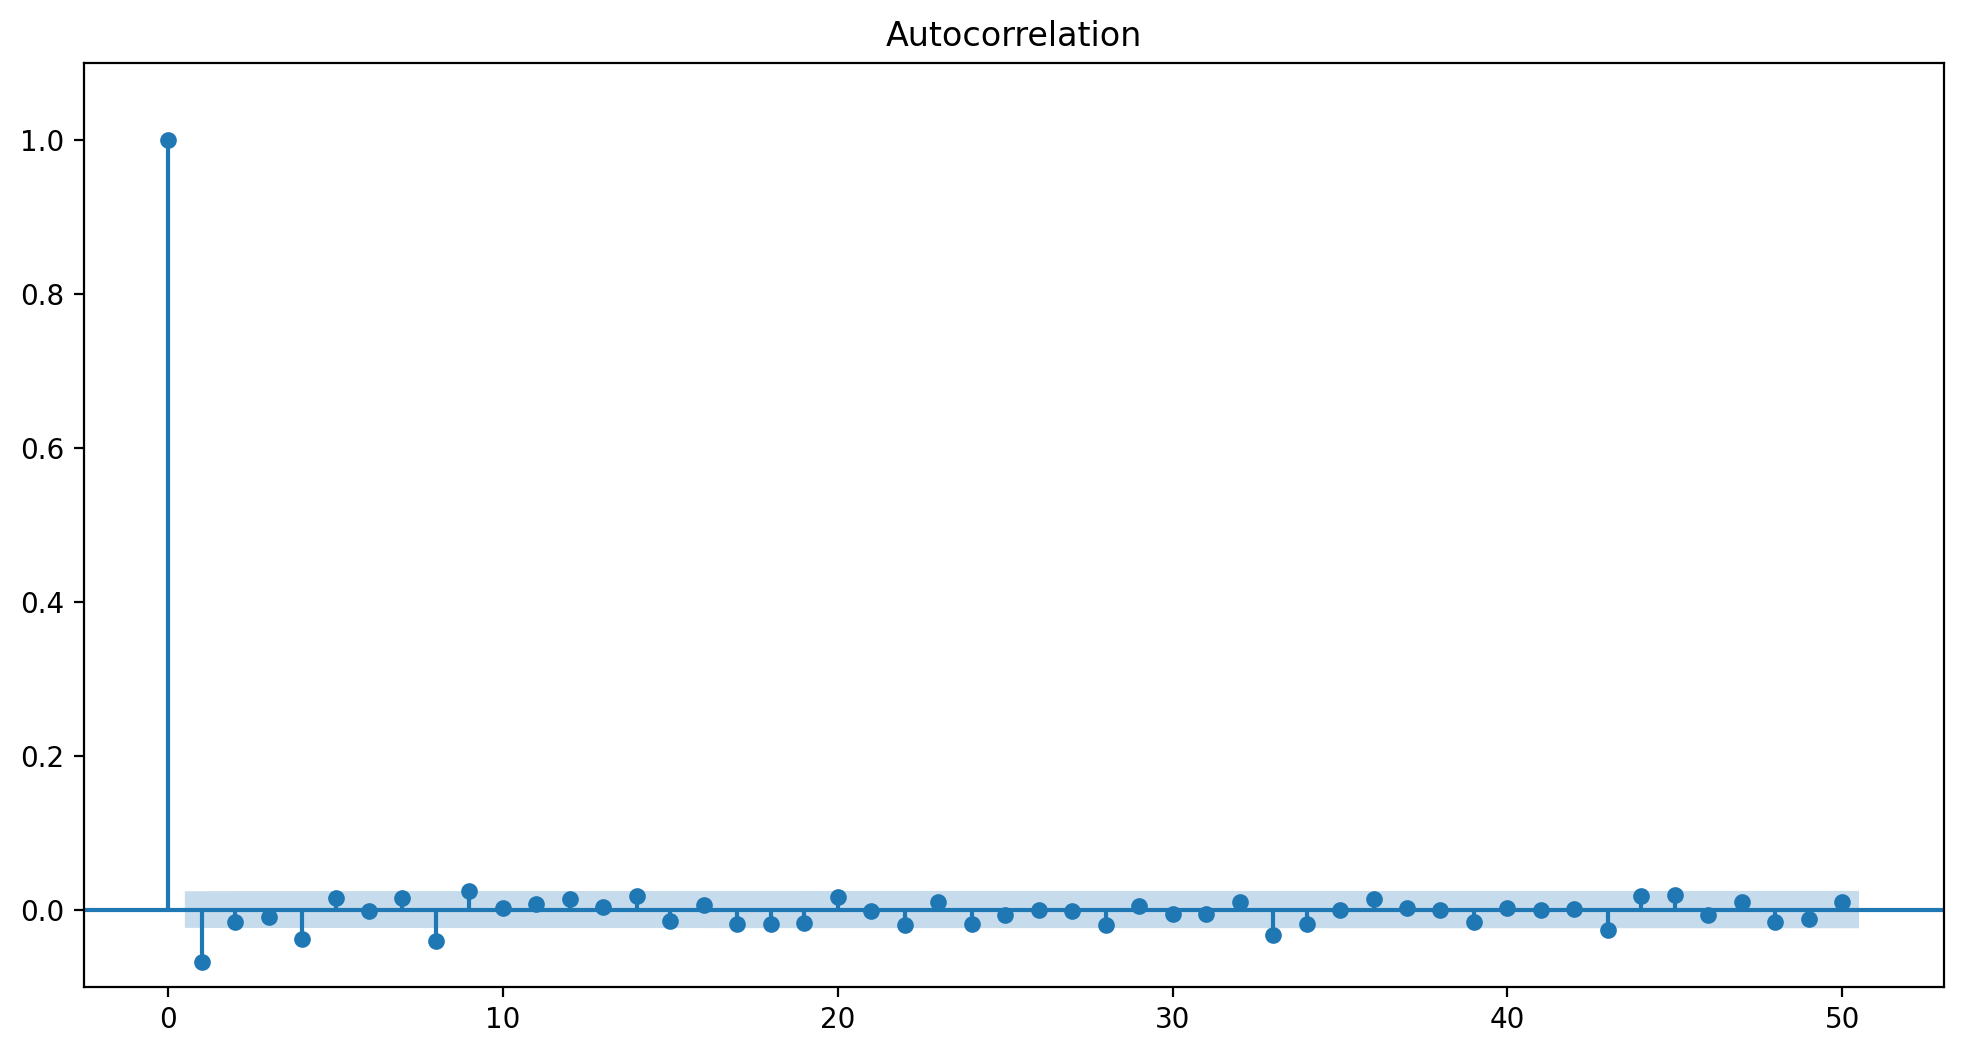

In [42]:
df.dropna(axis=0, inplace=True)

fig,ax = plt.subplots(figsize=(12,6))
acf = smt.graphics.plot_acf(df["log_rtn"],
        lags=N_LAGS,
        alpha=SIGNIFICANCE_LEVEL, ax=ax)

plt.ylim(-.1,1.1)

[Text(0, 0.5, 'Absolute Returns'), Text(0.5, 0, 'Lag')]

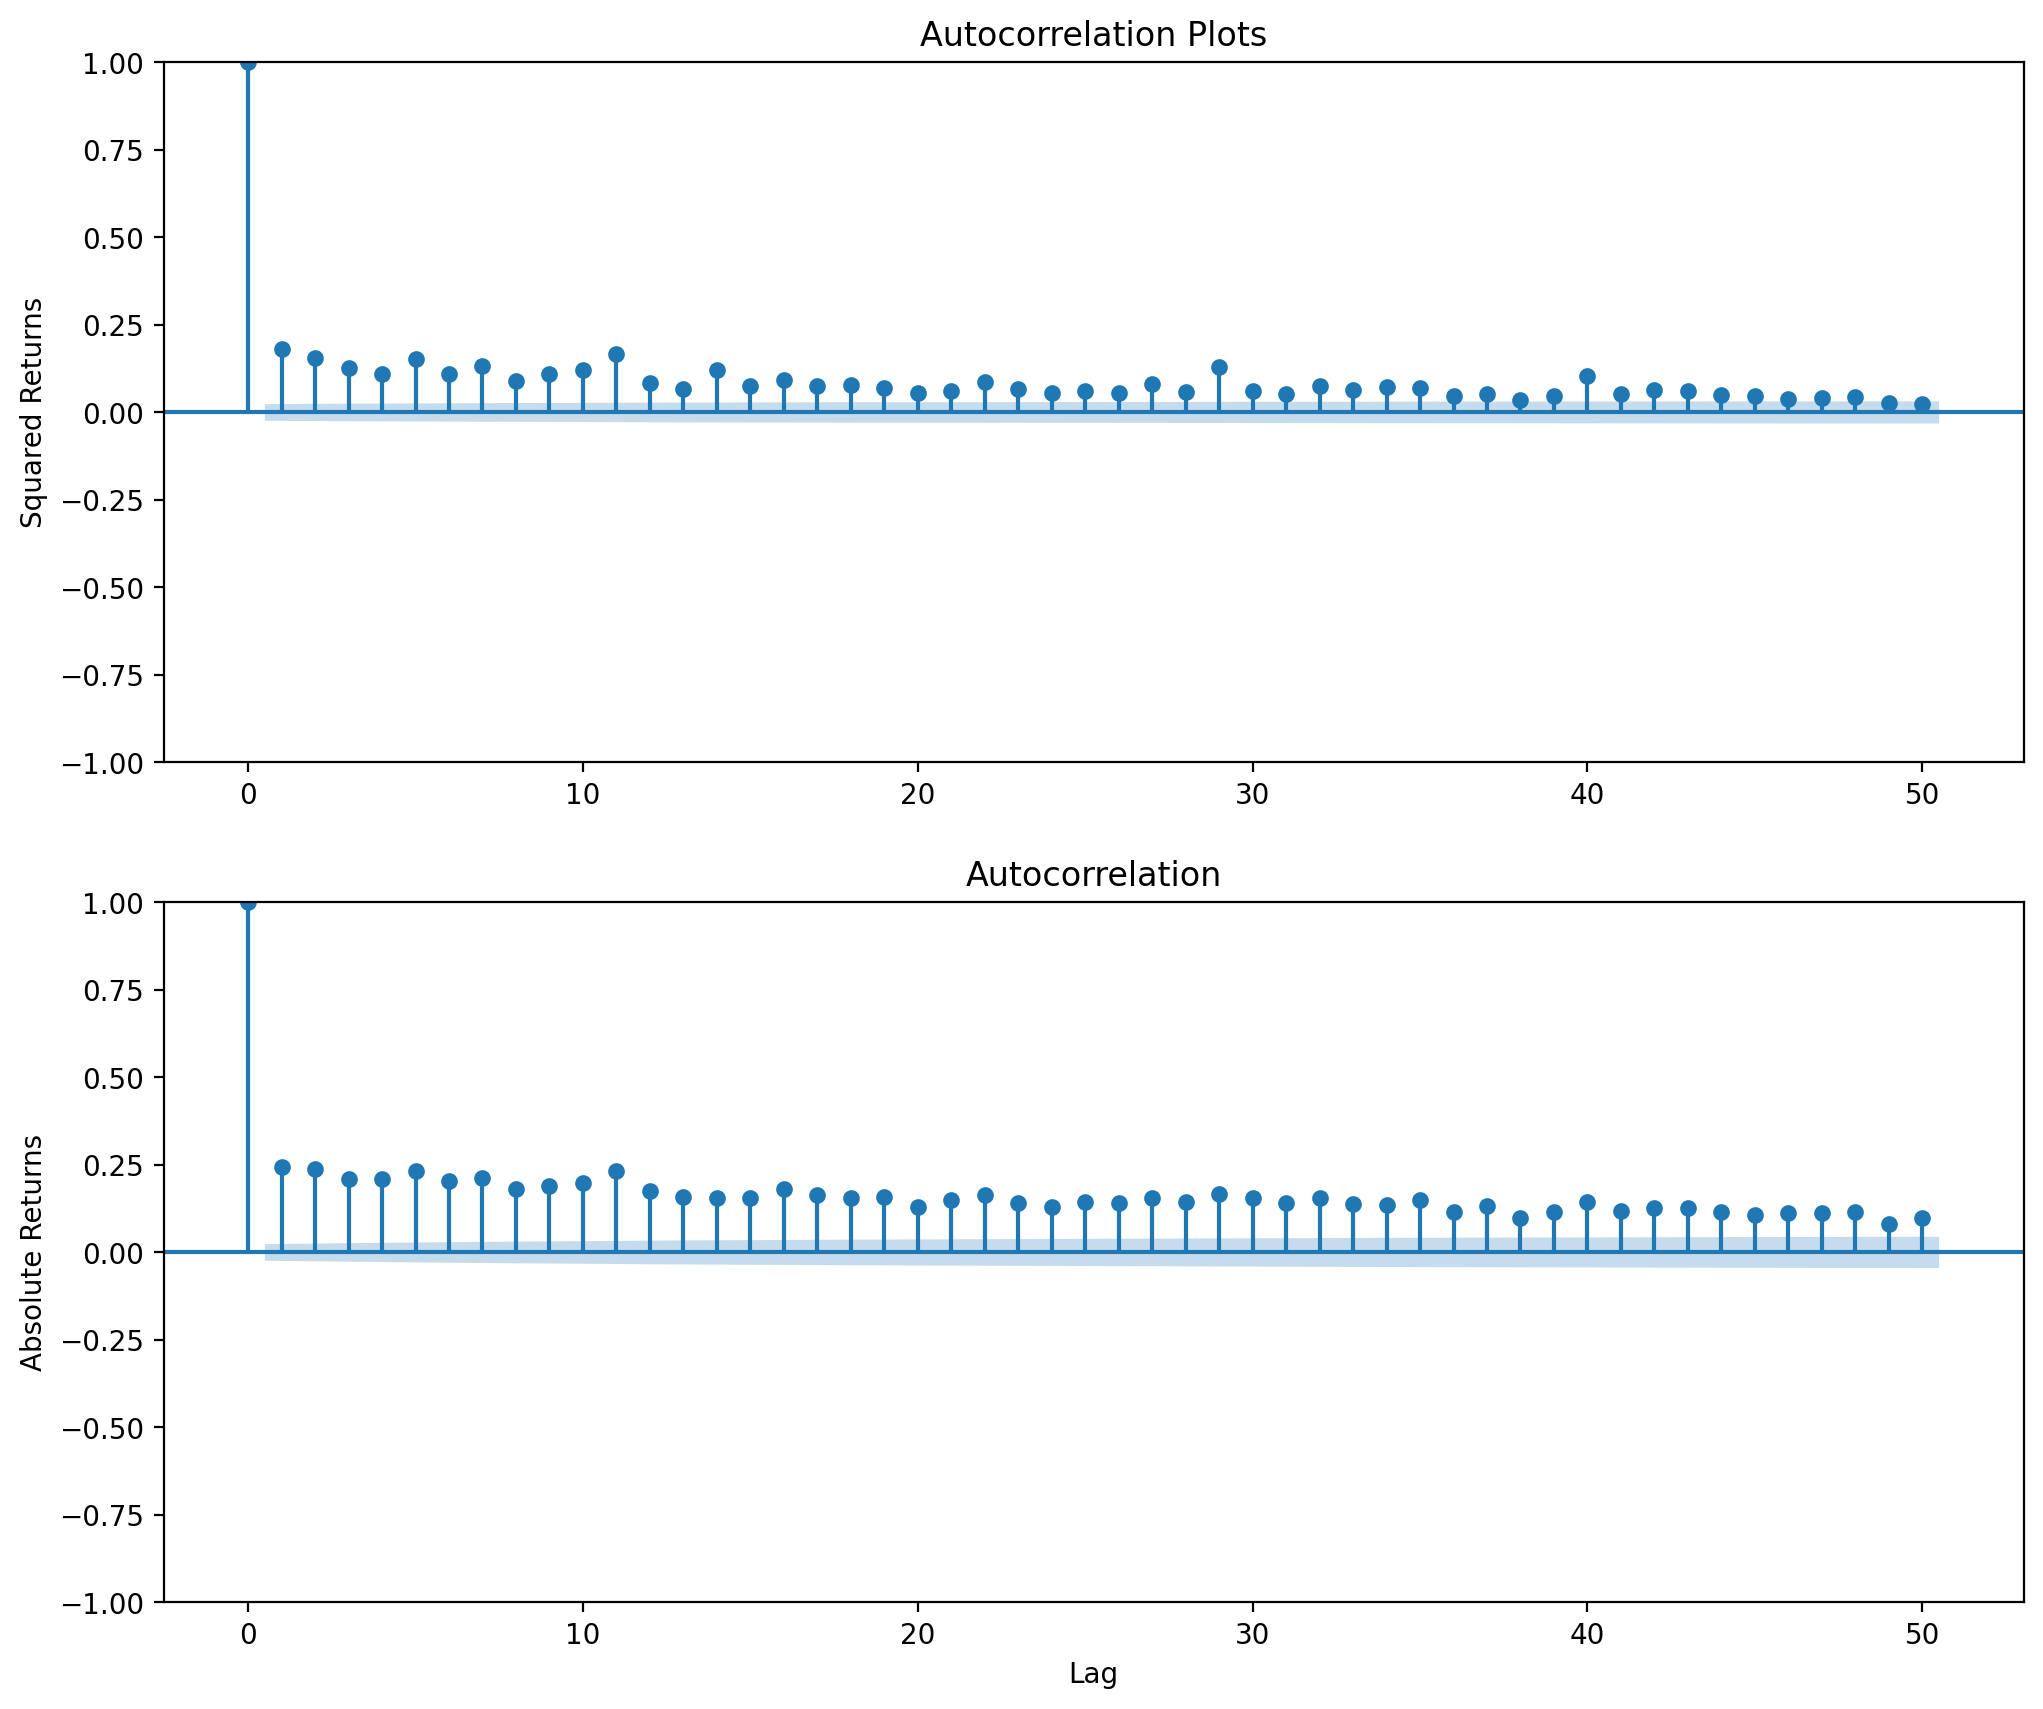

In [49]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10))
smt.graphics.plot_acf(df.log_rtn ** 2, lags=N_LAGS, alpha=SIGNIFICANCE_LEVEL, ax = ax[0])
ax[0].set(title='Autocorrelation Plots', ylabel='Squared Returns')
smt.graphics.plot_acf(np.abs(df.log_rtn), lags=N_LAGS, alpha=SIGNIFICANCE_LEVEL, ax = ax[1])
ax[1].set(ylabel='Absolute Returns', xlabel='Lag')

# Leverage effect

In [50]:
df['moving_std_252'] = df[['log_rtn']].rolling(window=252).std()
df['moving_std_21'] = df[['log_rtn']].rolling(window=21).std()

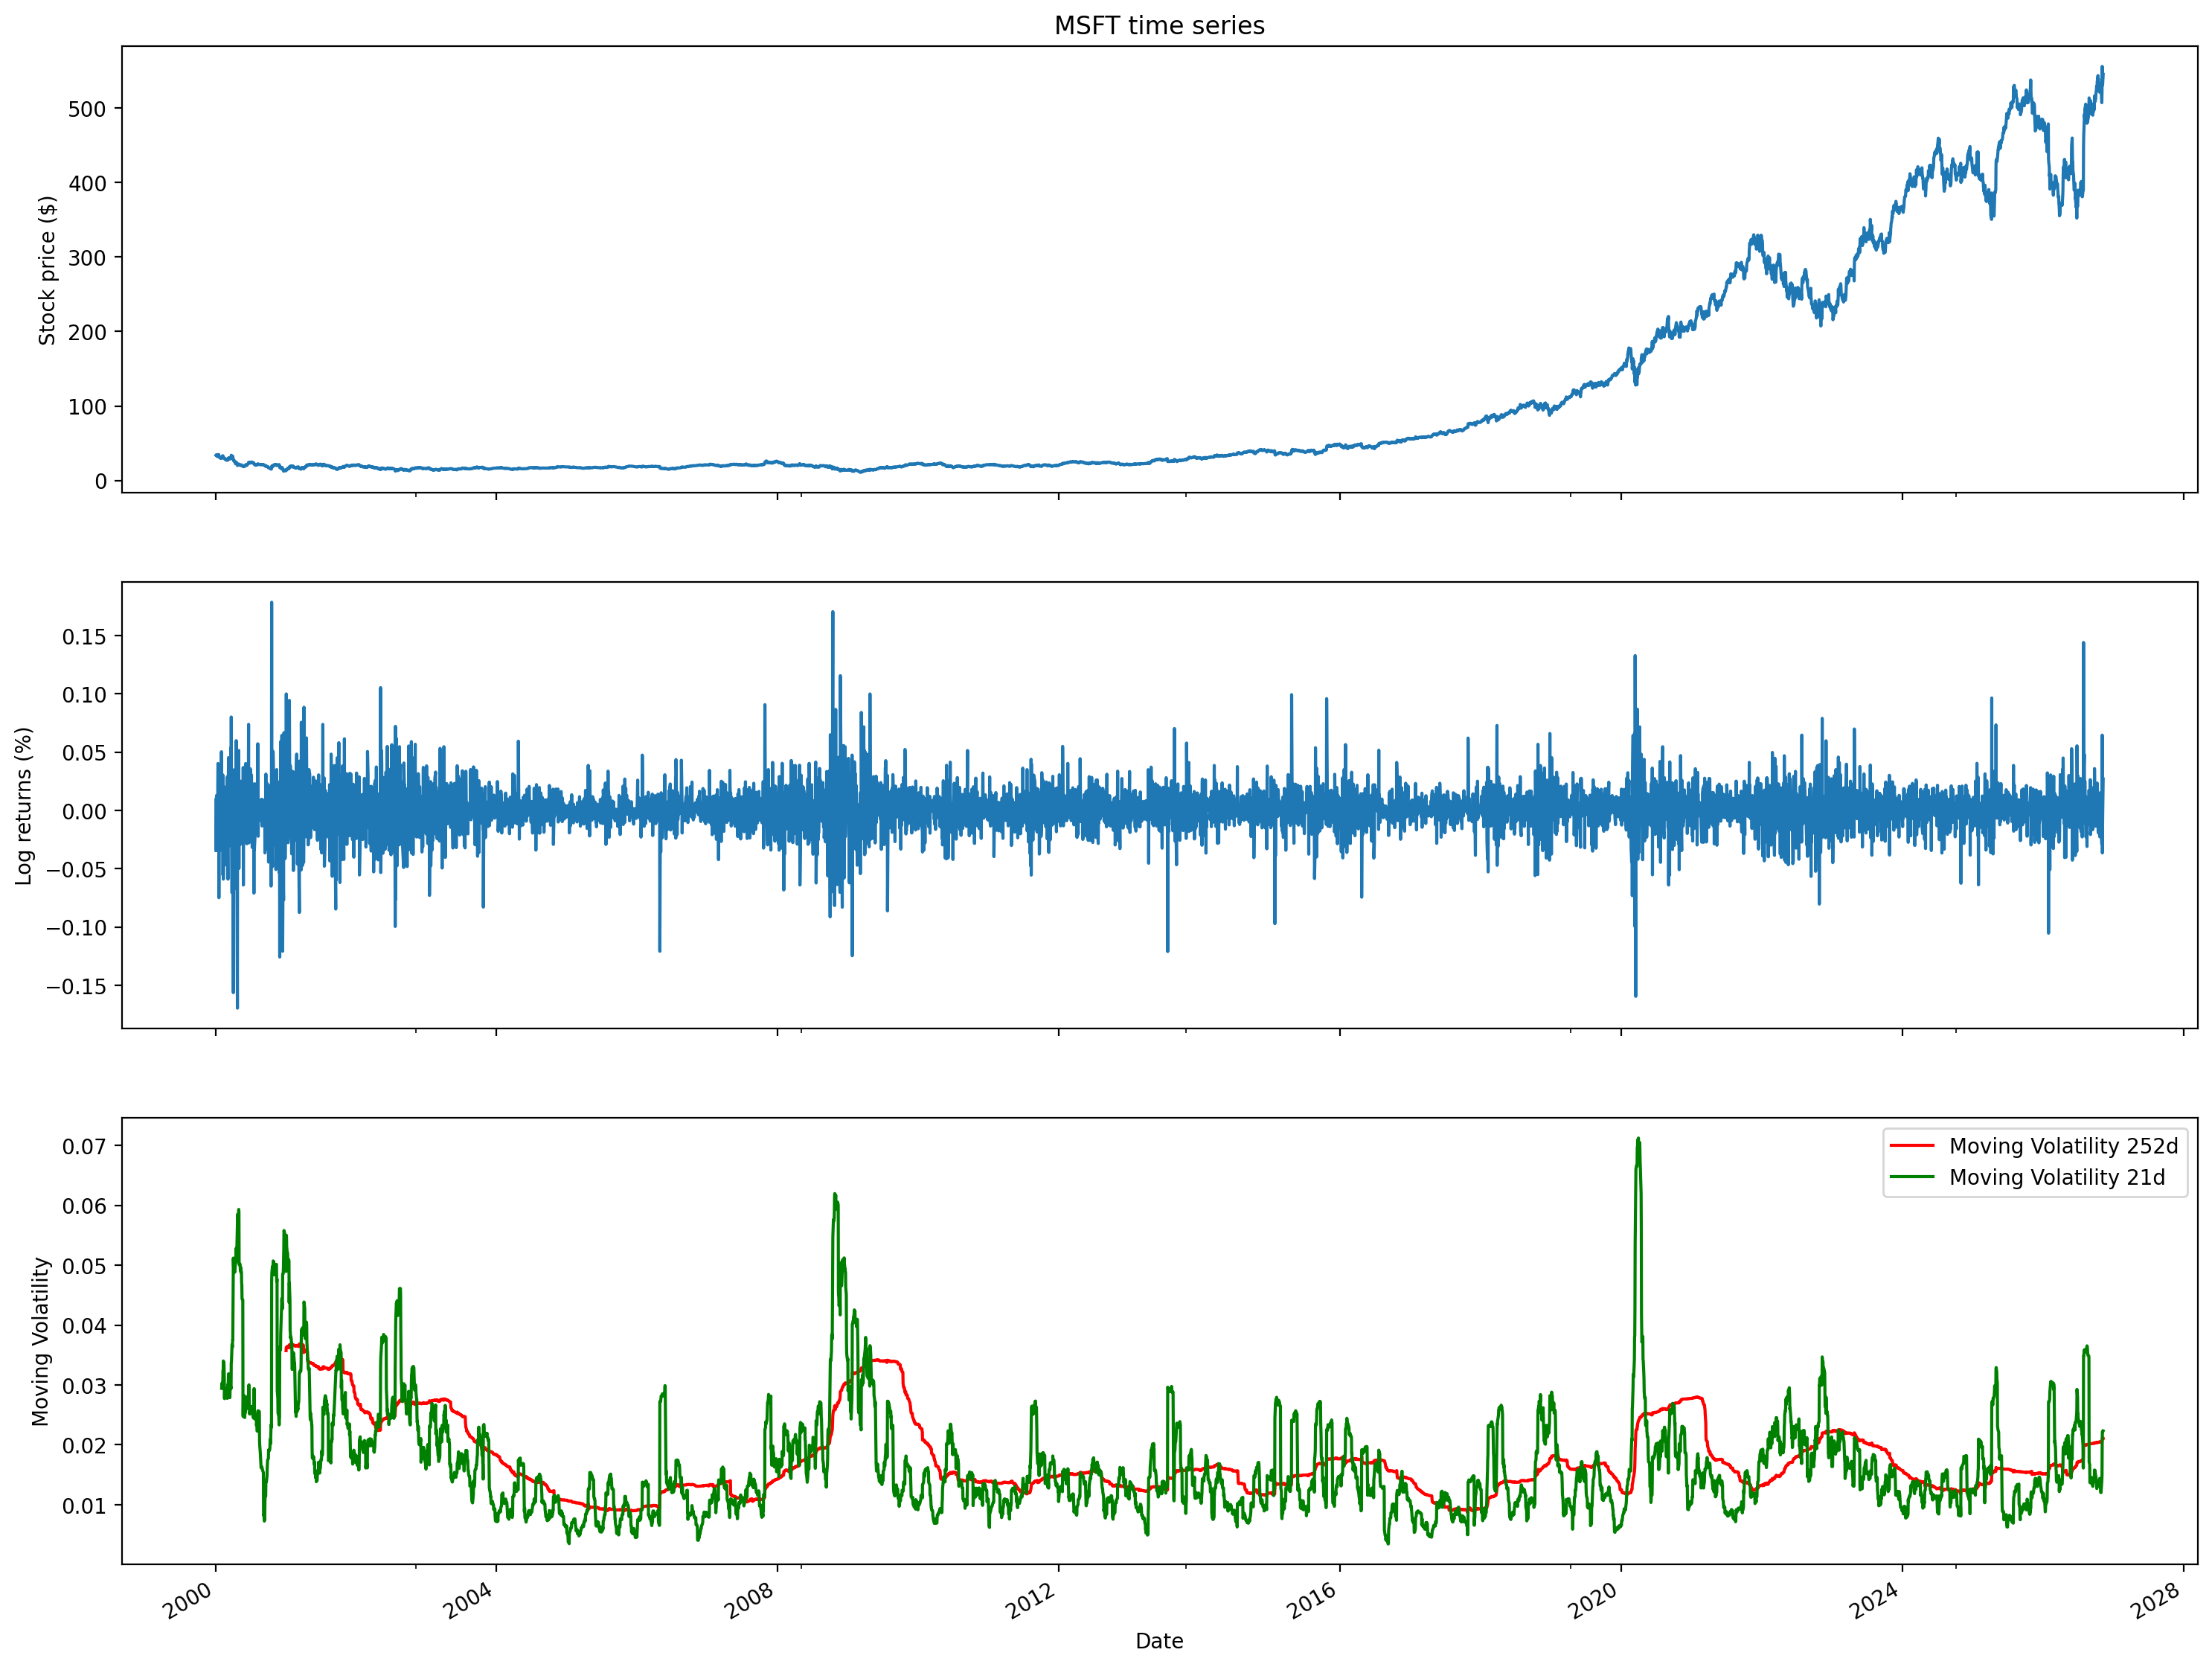

In [51]:
fig, ax = plt.subplots(3, 1, figsize=(18, 15), sharex=True)
df.close.plot(ax=ax[0])
ax[0].set(title='MSFT time series', ylabel='Stock price ($)')
df.log_rtn.plot(ax=ax[1])
ax[1].set(ylabel='Log returns (%)')
df.moving_std_252.plot(ax=ax[2], color='r', label='Moving Volatility 252d')
df.moving_std_21.plot(ax=ax[2], color='g', label='Moving Volatility 21d')
ax[2].set(ylabel='Moving Volatility', xlabel='Date')
ax[2].legend()

# VIX

In [56]:
df = yf.download(['^GSPC', '^VIX'], start='1985-01-01')
df = df[['Close']]
df.columns = df.columns.droplevel(0)
df = df.rename(columns={'^GSPC': 'sp500', '^VIX': 'vix'})
df

[*********************100%***********************]  2 of 2 completed


Ticker,sp500,vix
Date,,
1985-01-02,165.369995,NaN
1985-01-03,164.570007,NaN
1985-01-04,163.679993,NaN
1985-01-07,164.240005,NaN
1985-01-08,163.990005,NaN
...,...,...
2026-11-03,7568.919922,20.830000
2026-11-04,7688.620117,16.610001
2026-11-05,7353.729980,28.180000


In [58]:
df['log_rtn'] = np.log(df.sp500 / df.sp500.shift(1))
df['vol_rtn'] = np.log(df.vix / df.vix.shift(1))
df.dropna(how='any', axis=0, inplace=True)
df

Ticker,sp500,vix,log_rtn,vol_rtn
Date,,,,
1990-01-04,355.670013,19.219999,-0.008650,0.055079
1990-01-05,352.200012,20.110001,-0.009804,0.045266
1990-01-08,353.790009,20.260000,0.004504,0.007431
1990-01-09,349.619995,22.200001,-0.011857,0.091444
1990-01-10,347.309998,22.440001,-0.006629,0.010753
...,...,...,...,...
2026-11-03,7568.919922,20.830000,0.003643,-0.015246
2026-11-04,7688.620117,16.610001,0.015691,-0.226389
2026-11-05,7353.729980,28.180000,-0.044534,0.528608


In [ ]:
corr_coeff = df.log_rtn.corr(df.vol_rtn)
ax = sns.regplot(x='log_rtn', y='vol_rtn', data=df, line_kws={'color': 'red'})
ax.set(title=f'S&P 500 vs. VIX ($\\rho$ = {corr_coeff:.2f})', ylabel='VIX log returns',
xlabel='S&P 500 log returns')